# Task 2: Exploratory Data Analysis and Data Quality Assessment

## Project
Personalized TED Talks Recommendation System Using Machine Learning

## Objective
The objective of this notebook is to analyze the TED Talks dataset, understand its structure, identify missing values and duplicate records, examine text characteristics, explore tag frequencies, visualize important patterns, and propose a data-cleaning plan for the next development phase.

**Note:** The original datasets will remain unchanged during this analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [3]:
df1 = pd.read_csv(r"C:\Users\vramy\OneDrive\Desktop\samba-shiva-reddy\ted-talks-recommender\data\raw\ted_talks.csv")
df2 = pd.read_csv(r"C:\Users\vramy\OneDrive\Desktop\samba-shiva-reddy\ted-talks-recommender\data\raw\ted_transcripts.csv")

In [4]:
print("df1 shape is:", df1.shape)
print("df2 shape is:", df2.shape)

df1 shape is: (2550, 17)
df2 shape is: (2467, 2)


In [5]:
df1.head(2)

,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520


In [6]:
df2.head(2)

,transcript,url
0,Good morning. How are you?(Laughter)It's been ...,https://www.ted.com/talks/ken_robinson_says_sc...
1,"Thank you so much, Chris. And it's truly a gre...",https://www.ted.com/talks/al_gore_on_averting_...


In [7]:
print("df1 columns are:", df1.columns.tolist())
print("---------------------------------------------")
df1.info()

df1 columns are: ['comments', 'description', 'duration', 'event', 'film_date', 'languages', 'main_speaker', 'name', 'num_speaker', 'published_date', 'ratings', 'related_talks', 'speaker_occupation', 'tags', 'title', 'url', 'views']
---------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2550 entries, 0 to 2549
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   comments            2550 non-null   int64
 1   description         2550 non-null   str  
 2   duration            2550 non-null   int64
 3   event               2550 non-null   str  
 4   film_date           2550 non-null   int64
 5   languages           2550 non-null   int64
 6   main_speaker        2550 non-null   str  
 7   name                2550 non-null   str  
 8   num_speaker         2550 non-null   int64
 9   published_date      2550 non-null   int64
 10  ratings             2550 non-null   str  
 11  related_ta

In [8]:
display(df1.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
comments,2550.0,NaN,NaN,NaN,191.562353,282.315223,2.0,63.0,118.0,221.75,6404.0
description,2550,2550,Sir Ken Robinson makes an entertaining and pro...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,2550.0,NaN,NaN,NaN,826.510196,374.009138,135.0,577.0,848.0,1046.75,5256.0
event,2550,355,TED2014,84,NaN,NaN,NaN,NaN,NaN,NaN,NaN
film_date,2550.0,NaN,NaN,NaN,1321927552.047059,119739059.699232,74649600.0,1257465600.0,1333238400.0,1412964000.0,1503792000.0
languages,2550.0,NaN,NaN,NaN,27.326275,9.563452,0.0,23.0,28.0,33.0,72.0
main_speaker,2550,2156,Hans Rosling,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,2550,2550,Ken Robinson: Do schools kill creativity?,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_speaker,2550.0,NaN,NaN,NaN,1.028235,0.207705,1.0,1.0,1.0,1.0,5.0
published_date,2550.0,NaN,NaN,NaN,1343525265.750588,94640090.798582,1151367060.0,1268462970.0,1340935446.5,1423432130.25,1506092422.0


In [9]:
print("df2 columns are:", df2.columns.tolist())
print("---------------------------------------------------------")
df2.info()

df2 columns are: ['transcript', 'url']
---------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2467 entries, 0 to 2466
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   transcript  2467 non-null   str  
 1   url         2467 non-null   str  
dtypes: str(2)
memory usage: 38.7 KB


In [10]:
display(df2.describe(include="all"))

,transcript,url
count,2467,2467
unique,2464,2464
top,I have a question for you: Are you religious? ...,https://www.ted.com/talks/jonathan_haidt_human...
freq,2,2


In [11]:
print("Unique df1 URLs:", df1["url"].nunique())
print("Unique df2 URLs:", df2["url"].nunique())

Unique df1 URLs: 2550
Unique df2 URLs: 2464


In [12]:
print("Missing values count in each column in df1 are:")
df1.isnull().sum()

Missing values count in each column in df1 are:


comments              0
description           0
duration              0
event                 0
film_date             0
languages             0
main_speaker          0
name                  0
num_speaker           0
published_date        0
ratings               0
related_talks         0
speaker_occupation    6
tags                  0
title                 0
url                   0
views                 0
dtype: int64

In [13]:
print("Missing values percentage in each column in df1 are:")
df1.isnull().mean() * 100

Missing values percentage in each column in df1 are:


comments              0.000000
description           0.000000
duration              0.000000
event                 0.000000
film_date             0.000000
languages             0.000000
main_speaker          0.000000
name                  0.000000
num_speaker           0.000000
published_date        0.000000
ratings               0.000000
related_talks         0.000000
speaker_occupation    0.235294
tags                  0.000000
title                 0.000000
url                   0.000000
views                 0.000000
dtype: float64

In [14]:
print("Missing values count in each column in df2 are:")
df2.isnull().sum()

Missing values count in each column in df2 are:


transcript    0
url           0
dtype: int64

In [15]:
print("Missing values percentage in each column in df2 are:")
df2.isnull().mean() * 100

Missing values percentage in each column in df2 are:


transcript    0.0
url           0.0
dtype: float64

In [16]:
print("Duplicate rows in df1 are:",df1.duplicated().sum())
print("Duplicate rows in df2 are:",df2.duplicated().sum())

Duplicate rows in df1 are: 0
Duplicate rows in df2 are: 3


In [17]:
# Description analysis
df1["description_length"] = (df1["description"].fillna("").astype(str).str.len())

df1["description_word_count"] = (df1["description"].fillna("").astype(str).str.split().str.len())

# Transcript analysis
df2["transcript_length"] = (df2["transcript"].fillna("").astype(str).str.len())

df2["transcript_word_count"] = (df2["transcript"].fillna("").astype(str).str.split().str.len())

display(df1[["description_length", "description_word_count"]].describe())
display(df2[["transcript_length", "transcript_word_count"]].describe())

,description_length,description_word_count
count,2550.000000,2550.000000
mean,313.656078,51.850588
std,106.381571,18.112201
min,52.000000,9.000000
25%,236.000000,39.000000
50%,296.000000,49.000000
75%,379.000000,63.000000
max,769.000000,130.000000


,transcript_length,transcript_word_count
count,2467.000000,2467.000000
mean,11438.532631,2040.279287
std,5291.779202,956.209248
min,17.000000,1.000000
25%,7568.000000,1332.500000
50%,11539.000000,2028.000000
75%,15119.000000,2707.000000
max,51355.000000,9044.000000


In [18]:
print("Empty descriptions:",df1["description"].fillna("").astype(str).str.strip().eq("").sum())

print("Empty transcripts:",df2["transcript"].fillna("").astype(str).str.strip().eq("").sum())

print("Transcripts with fewer than 10 words:",(df2["transcript_word_count"] < 10).sum())

Empty descriptions: 0
Empty transcripts: 0
Transcripts with fewer than 10 words: 7


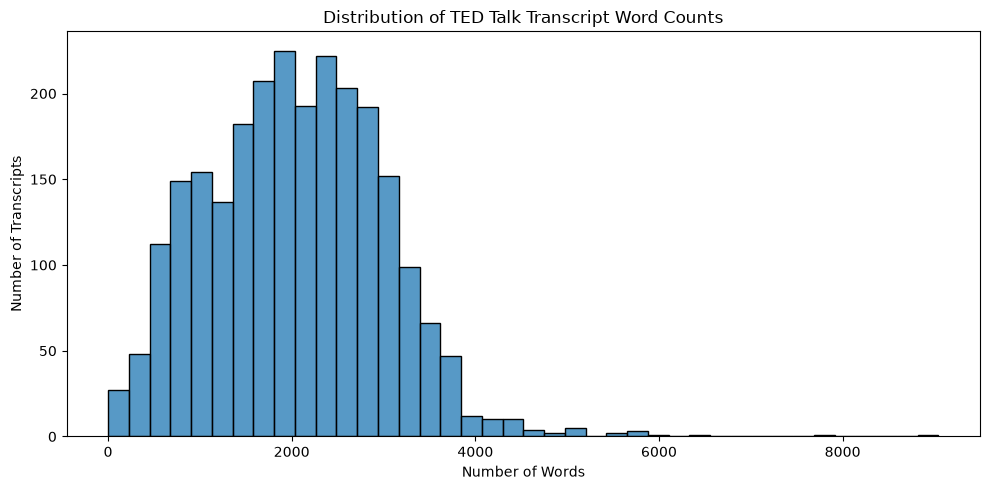

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df2,x="transcript_word_count",bins=40)

plt.title("Distribution of TED Talk Transcript Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Transcripts")
plt.tight_layout()
plt.show()

In [20]:
def parse_tags(value):
    if not isinstance(value, str):
        return []

    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

tags_list = df1["tags"].apply(parse_tags)

tag_counts = (tags_list.explode().dropna().astype(str).str.strip().loc[lambda s: s.ne("")].value_counts())

display(tag_counts.head(15))

tags
technology       727
science          567
global issues    501
culture          486
TEDx             450
design           418
business         348
entertainment    299
health           236
innovation       229
society          224
art              221
social change    218
future           195
communication    191
Name: count, dtype: int64

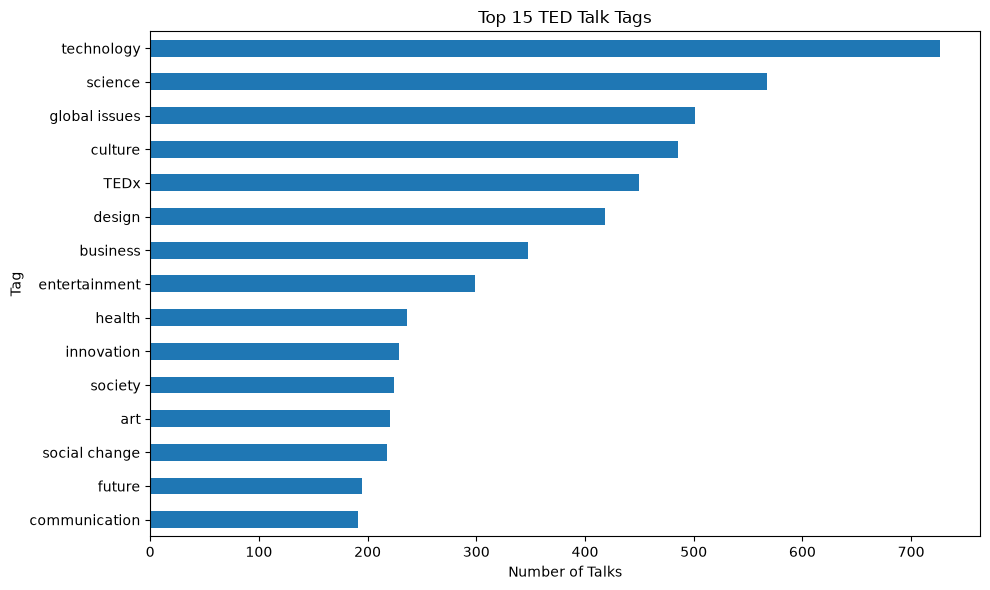

In [21]:
plt.figure(figsize=(10, 6))

tag_counts.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 TED Talk Tags")
plt.xlabel("Number of Talks")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()

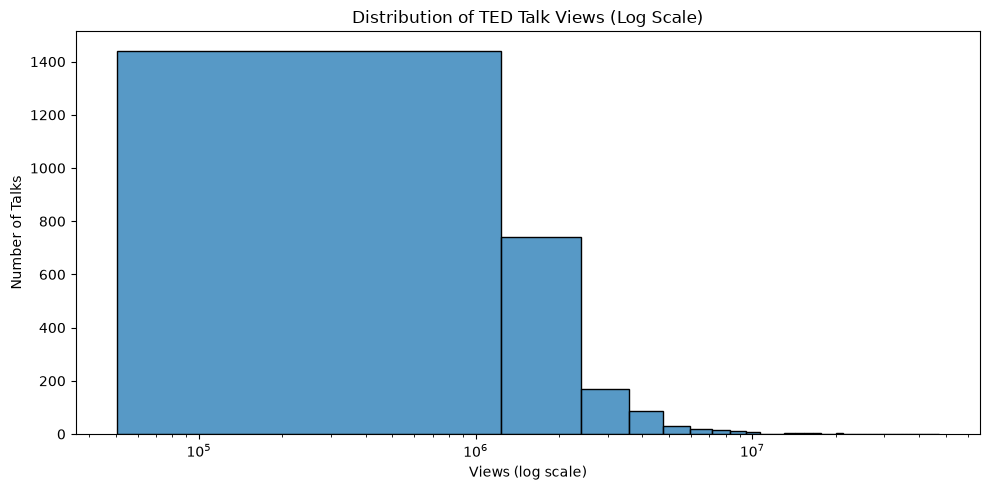

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df1[df1["views"] > 0],x="views",bins=40)

plt.xscale("log")
plt.title("Distribution of TED Talk Views (Log Scale)")
plt.xlabel("Views (log scale)")
plt.ylabel("Number of Talks")
plt.tight_layout()
plt.show()

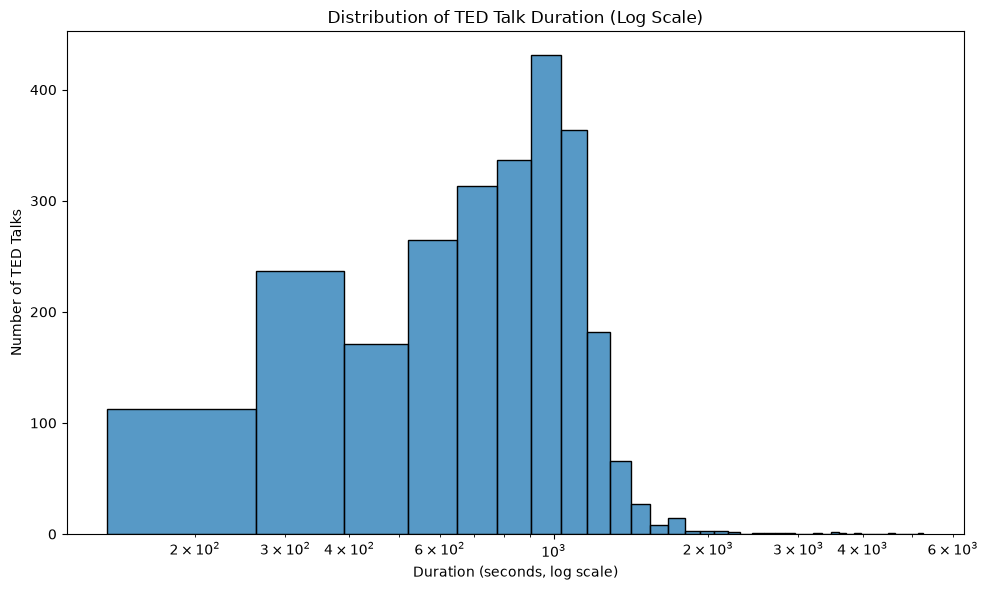

In [23]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df1[df1["duration"] > 0],x="duration",bins=40)

plt.xscale("log")

plt.title("Distribution of TED Talk Duration (Log Scale)")
plt.xlabel("Duration (seconds, log scale)")
plt.ylabel("Number of TED Talks")

plt.tight_layout()
plt.show()

In [24]:
numeric_columns = ["views","duration","comments","languages","num_speaker"]

display(df1[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
views,2550.0,1.698297e+06,2.498479e+06,50443.0,755792.75,1124523.5,1700759.50,47227110.0
duration,2550.0,8.265102e+02,3.740091e+02,135.0,577.00,848.0,1046.75,5256.0
comments,2550.0,1.915624e+02,2.823152e+02,2.0,63.00,118.0,221.75,6404.0
languages,2550.0,2.732627e+01,9.563452e+00,0.0,23.00,28.0,33.00,72.0
num_speaker,2550.0,1.028235e+00,2.077047e-01,1.0,1.00,1.0,1.00,5.0


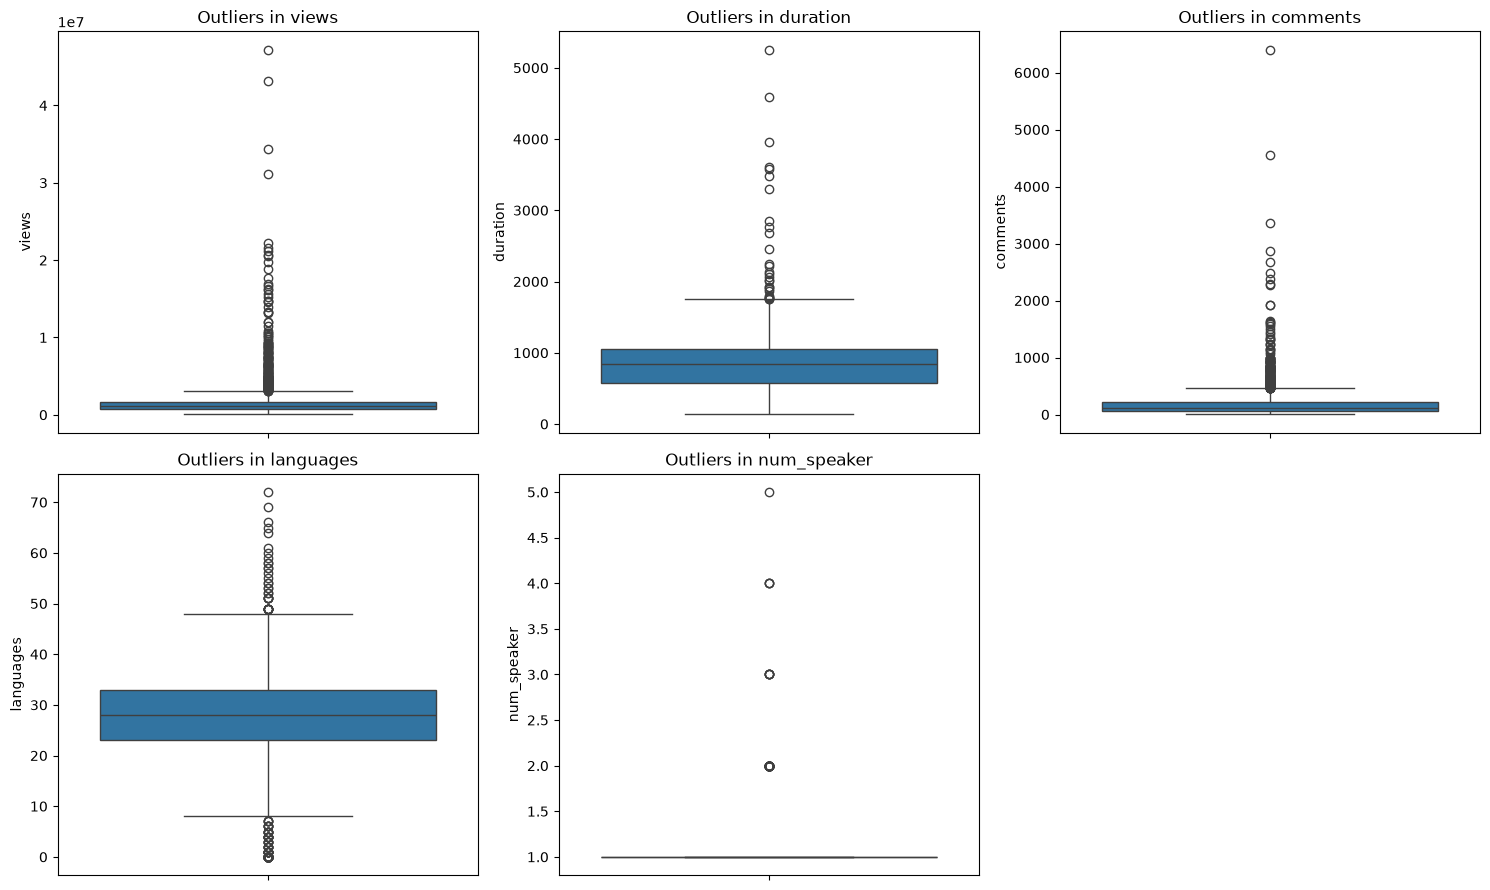

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(numeric_columns, axes.flat):
    sns.boxplot(y=df1[col], ax=ax)
    ax.set_title(f"Outliers in {col}")

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
def detect_outliers_iqr(data, column):
    values = data[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[
        (values < lower) | (values > upper)
    ]

    return {
        "Column": column,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(values) * 100
        if len(values) else 0
    }

outlier_report = pd.DataFrame([
    detect_outliers_iqr(df1, col)
    for col in numeric_columns
])

display(outlier_report)

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,views,-661657.375,3118209.625,246,9.647059
1,duration,-127.625,1751.375,28,1.098039
2,comments,-175.125,459.875,200,7.843137
3,languages,8.000,48.000,164,6.431373
4,num_speaker,1.000,1.000,58,2.274510


In [27]:
Q1 = df1["views"].quantile(0.25)
Q3 = df1["views"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

view_outliers = df1[df1["views"] > upper_bound]

display(
    view_outliers[
        ["title", "main_speaker", "views"]
    ].sort_values("views", ascending=False).head(10)
)

,title,main_speaker,views
0,Do schools kill creativity?,Ken Robinson,47227110
1346,Your body language may shape who you are,Amy Cuddy,43155405
677,How great leaders inspire action,Simon Sinek,34309432
837,The power of vulnerability,Brené Brown,31168150
452,10 things you didn't know about orgasm,Mary Roach,22270883
1776,How to speak so that people want to listen,Julian Treasure,21594632
201,My stroke of insight,Jill Bolte Taylor,21190883
5,Why we do what we do,Tony Robbins,20685401
2114,This is what happens when you reply to spam email,James Veitch,20475972
1416,"Looks aren't everything. Believe me, I'm a model.",Cameron Russell,19787465


In [28]:
Q1 = df1["duration"].quantile(0.25)
Q3 = df1["duration"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

view_outliers = df1[df1["duration"] > upper_bound]

display(
    view_outliers[
        ["title", "main_speaker", "duration"]
    ].sort_values("duration", ascending=False).head(10)
)

,title,main_speaker,duration
640,"Parrots, the universe and everything",Douglas Adams,5256
588,Really achieving your childhood dreams,Randy Pausch,4587
629,Physics is fun to imagine,Richard Feynman,3955
2387,Nationalism vs. globalism: the new political d...,Yuval Noah Harari,3608
594,Stories of Haiti,Edwidge Danticat,3573
600,Growing up in the universe,Richard Dawkins,3475
580,What's the right thing to do?,Michael Sandel,3296
2421,Political common ground in a polarized United ...,"Gretchen Carlson, David Brooks",2853
947,Authentic creativity vs. karaoke culture,Malcolm McLaren,2761
202,My days as a young rebel,Frank Gehry,2678


In [29]:
Q1 = df1["comments"].quantile(0.25)
Q3 = df1["comments"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

view_outliers = df1[df1["comments"] > upper_bound]

display(
    view_outliers[
        ["title", "main_speaker", "comments"]
    ].sort_values("comments", ascending=False).head(10)
)

,title,main_speaker,comments
96,Militant atheism,Richard Dawkins,6404
0,Do schools kill creativity?,Ken Robinson,4553
644,Science can answer moral questions,Sam Harris,3356
201,My stroke of insight,Jill Bolte Taylor,2877
1787,How do you explain consciousness?,David Chalmers,2673
954,Taking imagination seriously,Janet Echelman,2492
840,On reading the Koran,Lesley Hazleton,2374
1346,Your body language may shape who you are,Amy Cuddy,2290
661,The danger of science denial,Michael Specter,2272
677,How great leaders inspire action,Simon Sinek,1930


In [30]:
Q1 = df1["languages"].quantile(0.25)
Q3 = df1["languages"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

view_outliers = df1[df1["languages"] > upper_bound]

display(
    view_outliers[
        ["title", "main_speaker", "languages"]
    ].sort_values("languages", ascending=False).head(10)
)

,title,main_speaker,languages
973,Try something new for 30 days,Matt Cutts,72
606,"Weird, or just different?",Derek Sivers,69
47,8 secrets of success,Richard St. John,66
653,How to start a movement,Derek Sivers,65
479,Teach statistics before calculus!,Arthur Benjamin,64
239,The ancestor of language,Murray Gell-Mann,61
0,Do schools kill creativity?,Ken Robinson,60
940,How to tie your shoes,Terry Moore,59
654,What adults can learn from kids,Adora Svitak,58
758,Keep your goals to yourself,Derek Sivers,58


In [31]:
Q1 = df1["num_speaker"].quantile(0.25)
Q3 = df1["num_speaker"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

view_outliers = df1[df1["num_speaker"] > upper_bound]

display(
    view_outliers[
        ["title", "main_speaker", "num_speaker"]
    ].sort_values("num_speaker", ascending=False).head(10)
)

,title,main_speaker,num_speaker
2507,A dance to honor Mother Earth,Jon Boogz and Lil Buck,5
1543,The interspecies internet? An idea in progress,"Diana Reiss, Peter Gabriel, Neil Gershenfeld a...",4
2421,Political common ground in a polarized United ...,"Gretchen Carlson, David Brooks",4
2334,An interview with the founders of Black Lives ...,"Alicia Garza, Patrisse Cullors and Opal Tometi",4
1971,"The dancer, the singer, the cellist ... and a ...",Bill T. Jones,3
2319,"""Space Oddity""","Amanda Palmer, Jherek Bischoff, Usman Riaz",3
1107,Award-winning teenage science in action,"Lauren Hodge, Shree Bose + Naomi Shah",3
2215,My journey from Marine to actor,Adam Driver,3
796,"""(Nothing But) Flowers"" with string quartet","David Byrne, Ethel + Thomas Dolby",3
98,"""La Vie en Rose""",Rachelle Garniez,2


# Exploratory Data Analysis and Data Quality Report

## 1. Key Findings

### 1. Dataset Size

The main TED Talks dataset contains **2,550 rows and 17 columns**, while the transcript dataset contains **2,467 rows and 2 columns**. The main dataset includes talk details, speaker information, descriptions, tags, and popularity metrics. The transcript dataset contains talk transcripts and their corresponding URLs.

### 2. Missing Values

The main dataset contains **6 missing values** in the `speaker_occupation` column. The transcript dataset has **0 missing values**.

The missing speaker occupations will be handled during data cleaning by replacing them with `"Unknown"` so that useful talk records are retained.

### 3. Duplicate Records

The main dataset contains **0 duplicate rows**. The transcript dataset contains **3 exact duplicate rows**. These duplicates will be investigated and handled during the data-cleaning phase. Repeated URLs will also be checked separately to ensure that each talk is associated with an appropriate transcript.

### 4. Transcript Availability

A total of **2,464 main talks have matching transcripts**, while **86 talks do not have matching transcripts**. These talks can still be used for recommendations based on their available titles, descriptions, and tags.

The transcript dataset contains no URLs that are absent from the main dataset, according to the URL comparison performed during initial exploration.

### 5. Text Characteristics

The average transcript contains approximately **2,040 words**. Transcript lengths will be analyzed to understand variation in talk content and identify unusually short or long transcripts.

The title, description, tags, and transcript are the primary text fields considered for the content-based recommendation system.

### 6. Topic Distribution

The most frequent TED Talk tags were identified as **technology, science, and global issues** in the initial analysis. The top 15 tags will be visualized to better understand the common topics represented in the dataset.

The tags will be retained as text features because they provide useful information about the subject of each talk.

### 7. Views Distribution

The `views` column will be analyzed to understand differences in talk popularity. The distribution will be examined using descriptive statistics and visualizations to identify highly viewed talks and understand whether the values are strongly skewed.

High view counts will not automatically be considered data errors because they may represent genuine popularity.

### 8. Outlier Analysis

The Interquartile Range (IQR) method was applied to the `views`, `duration`, `comments`, `languages`, and `num_speaker` columns to identify potential outliers.

| Column | Outlier Count | Outlier Percentage |
|---|---:|---:|
| `views` | 246 | 9.65% |
| `duration` | 28 | 1.10% |
| `comments` | 200 | 7.84% |
| `languages` | 164 | 6.43% |
| `num_speaker` | 58 | 2.27% |

#### Interpretation of Outliers

- **Views:** The highest-viewed talks include popular presentations with millions of views. These values appear plausible and will be retained unless an actual data error is discovered.
- **Duration:** Some talks have durations exceeding the calculated IQR upper bound of approximately 29 minutes and 11 seconds. These may be valid longer presentations and will not be removed automatically.
- **Comments:** The IQR method identified 200 potential outliers. Their values will be inspected before deciding whether any correction is necessary.
- **Languages:** Some talks have language counts ranging from 58 to 72 in the inspected records. These values may reflect the availability of translations and are not necessarily errors.
- **Number of speakers:** The IQR method identified talks with multiple speakers because the calculated lower and upper bounds were both 1. These talks may be legitimate performances, interviews, or panel discussions.

#### Outlier Analysis Conclusion

The IQR method identifies statistically unusual values, but it does not establish that those values are incorrect. Therefore, outliers will not be deleted or capped automatically. Valid observations will be retained, and only confirmed data errors will be corrected or excluded after investigation.

The `languages` and `num_speaker` columns may be excluded during feature selection because they are not required for the planned text-based recommendation model. Excluding a column will not remove the associated talks.

## 2. Proposed Data-Cleaning Plan

The following actions will be performed during the next task, Data Cleaning and Text Preprocessing.

### 1. Column Selection

Remove unnecessary columns and retain the fields required for the recommendation system.

From the main dataset, retain:

- `title`
- `description`
- `tags`
- `main_speaker`
- `speaker_occupation`
- `event`
- `views`
- `url`

From the transcript dataset, retain:

- `url`
- `transcript`

### 2. Missing-Value Handling

Replace the six missing values in `speaker_occupation` with `"Unknown"` to preserve useful talk records.

Other text fields will be checked for missing or empty values before preprocessing.

### 3. Duplicate Removal

Reload the original transcript dataset and verify the reported duplicate count. Check both exact duplicate rows and repeated URLs.

Remove confirmed duplicate records while retaining one appropriate transcript per talk. If repeated URLs have different transcript contents, investigate them before choosing which record to retain.

### 4. Missing Transcript Handling

Preserve the 86 talks without matching transcripts. These talks can still be recommended using their available titles, descriptions, and tags.

Missing transcripts will be handled using empty strings when creating the combined text field, rather than removing the associated talks.

### 5. Text Preprocessing

Prepare the text fields for recommendation by applying appropriate cleaning techniques, such as:

- Handling missing text values.
- Removing unwanted stage directions from transcripts where appropriate.
- Correcting spacing and normalizing whitespace.
- Combining relevant text fields while preserving meaningful information.

The original raw text will remain unchanged.

### 6. Dataset Merging

Merge the selected main and transcript columns using `url` as the matching key.

A **left join** will be used so that all 2,550 talks from the main dataset remain in the merged dataset, including talks without transcripts.

### 7. Recommendation Feature Creation

Create a combined text column using:

- `title`
- `description`
- `tags`
- `transcript`

The combined text will serve as the input for the TF-IDF vectorizer. Cosine similarity will then be used to measure similarity between talks and generate recommendations.

The `event`, `views`, speaker metadata, and `url` fields will be retained as metadata where useful, but they will not be included in the combined recommendation text.

### 8. Outlier Handling

Do not remove or cap valid outliers solely because they fall outside the IQR bounds. Investigate suspicious numeric values and correct only confirmed errors.

The `languages` and `num_speaker` columns can be excluded during feature selection if they are not needed for the recommendation model. Their exclusion will not affect the retention of valid talks.

### 9. Preserving Raw Data

Keep the original CSV files unchanged in `data/raw/`.

Save the cleaned and merged dataset separately in `data/processed/` so that the original data remains available for verification and reproducibility.

## 3. Conclusion

The exploratory data analysis provided an overview of the TED Talks dataset, including its structure, missing values, duplicate records, transcript availability, text characteristics, topic distribution, views, and potential outliers.

The main dataset contains 2,550 talks, and 2,464 have matching transcripts. The remaining talks can still participate in the recommendation system using their available text fields.

The analysis also identified potential outliers in several numeric columns. These values will be investigated rather than removed automatically because many may represent valid characteristics of TED Talks.

The next stage is **Data Cleaning and Text Preprocessing**, followed by dataset merging, combined-text creation, TF-IDF vectorization, cosine similarity calculation, and recommendation-system development.